# Statistical Analysis: Salary Comparison Across Job Categories

## Project Overview

This notebook investigates differences in annual salary distributions
across four job categories:

- Business Analyst
- Data Analyst
- Data Engineer
- Data Scientist

The analysis uses non-parametric statistical methods to evaluate
whether salary distributions differ significantly across these roles.

## Research Questions

1. Do annual salary distributions differ across the four job categories?
2. Which pairs of job categories have statistically significant differences?
3. How large is the overall difference between the salary distributions?

## Statistical Methods

- Descriptive Statistics
- Kruskal-Wallis H Test
- Mann-Whitney U Test
- Holm-Bonferroni Correction
- Epsilon-Squared Effect Size

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(".env file not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(".env file not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

DATABASE_URL = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=int(DB_PORT),
    database=DB_NAME
)

engine = create_engine(DATABASE_URL)

print("Database connection established.")

Database connection established.


In [5]:
query_salary = """
SELECT
    job_id,
    job_title_short,
    salary_year_avg
FROM job_postings_fact
WHERE job_title_short IN (
    'Business Analyst',
    'Data Analyst',
    'Data Engineer',
    'Data Scientist'
)
AND salary_year_avg IS NOT NULL;
"""

df_salary = pd.read_sql_query(query_salary, engine)

print(f"Total observations: {len(df_salary):,}")
df_salary.head()

Total observations: 16,515


,job_id,job_title_short,salary_year_avg
0,50602,Data Analyst,85000.0
1,50729,Data Engineer,155000.0
2,51653,Data Engineer,221000.0
3,51751,Data Scientist,124000.0
4,51752,Data Scientist,139216.0


In [6]:
print("Dataset Information:")
print(df_salary.info())

print("\nMissing Values:")
print(df_salary.isnull().sum())

print("\nJob Category Distribution:")
print(df_salary['job_title_short'].value_counts())

print("\nDuplicate Job IDs:")
print(df_salary['job_id'].duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 16515 entries, 0 to 16514
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   job_id           16515 non-null  int64  
 1   job_title_short  16515 non-null  str    
 2   salary_year_avg  16515 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 387.2 KB
None

Missing Values:
job_id             0
job_title_short    0
salary_year_avg    0
dtype: int64

Job Category Distribution:
job_title_short
Data Scientist      5926
Data Analyst        5463
Data Engineer       4509
Business Analyst     617
Name: count, dtype: int64

Duplicate Job IDs:
0


## 1. Descriptive Statistics

This section examines the distribution of annual salaries across
Business Analyst, Data Analyst, Data Engineer, and Data Scientist roles.

The analysis includes measures of central tendency, dispersion,
quartiles, and skewness.

In [7]:
salary_summary = (
    df_salary
    .groupby('job_title_short')['salary_year_avg']
    .agg(
        count='count',
        mean='mean',
        median='median',
        std='std',
        minimum='min',
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        maximum='max',
        skewness='skew'
    )
    .round(2)
    .sort_values('median', ascending=False)
)

salary_summary

,count,mean,median,std,minimum,q1,q3,maximum,skewness
job_title_short,,,,,,,,,
Data Scientist,5926,135929.48,127500.0,52247.65,27000.0,100000.0,158857.5,960000.0,1.98
Data Engineer,4509,130266.87,125000.0,42503.07,15000.0,100000.0,147500.0,525000.0,1.55
Data Analyst,5463,93875.79,90000.0,34086.67,25000.0,70000.0,111175.0,650000.0,2.33
Business Analyst,617,91071.04,85000.0,31938.80,16500.0,71000.0,105000.0,387460.0,2.09


## 2. Salary Distribution

Boxplots are used to compare salary distributions across job categories.
They provide information about the median, interquartile range,
and potential outliers.

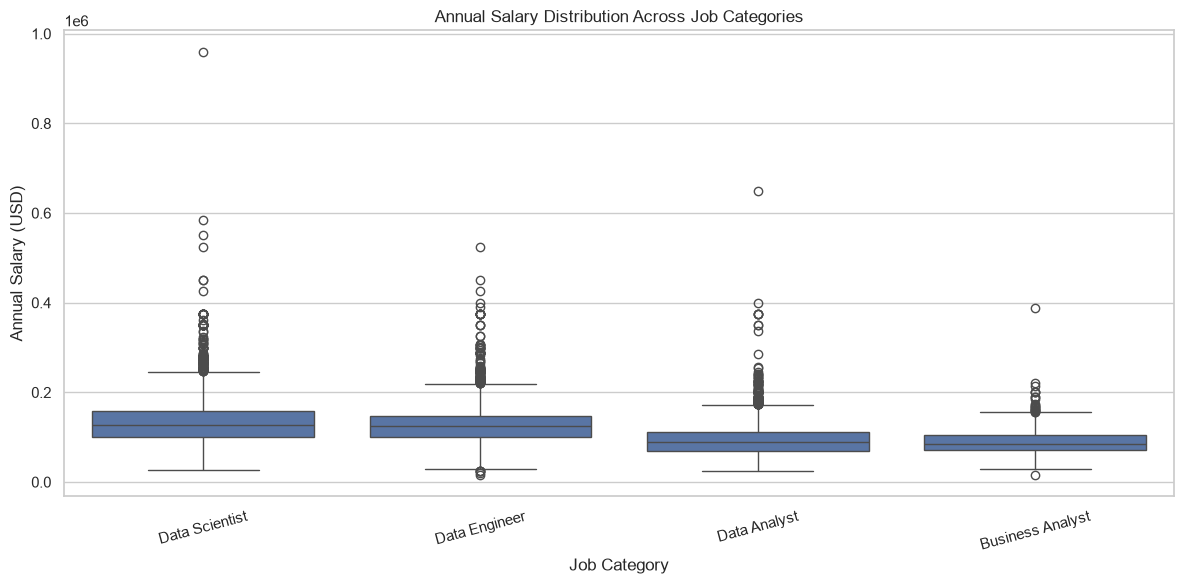

In [8]:
plt.figure(figsize=(12, 6))

category_order = (
    df_salary
    .groupby('job_title_short')['salary_year_avg']
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df_salary,
    x='job_title_short',
    y='salary_year_avg',
    order=category_order
)

plt.title('Annual Salary Distribution Across Job Categories')
plt.xlabel('Job Category')
plt.ylabel('Annual Salary (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 3. Mean vs Median Comparison

Comparing the mean and median helps identify differences in salary
distribution and the potential influence of extreme values.

A substantial gap between these measures may indicate a skewed distribution.

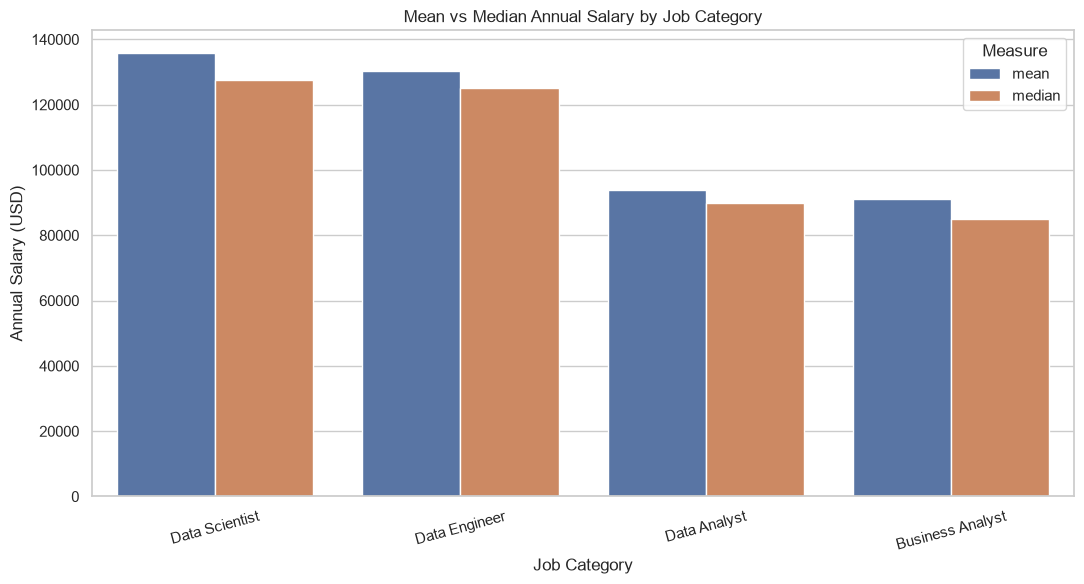

In [9]:
comparison = (
    salary_summary[['mean', 'median']]
    .reset_index()
    .melt(
        id_vars='job_title_short',
        var_name='measure',
        value_name='salary'
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison,
    x='job_title_short',
    y='salary',
    hue='measure'
)

plt.title('Mean vs Median Annual Salary by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Annual Salary (USD)')
plt.xticks(rotation=15)
plt.legend(title='Measure')
plt.tight_layout()
plt.show()

## 4. Kruskal-Wallis H Test

The Kruskal-Wallis H test is used to determine whether
annual salary distributions differ significantly across
the four job categories.

### Hypotheses

- H0: Annual salary distributions are identical across
  the four job categories.
- H1: At least one job category has a different
  annual salary distribution.

The significance level is set at 0.05.

In [10]:
# Separate salary data by job category

salary_groups = {
    category: group['salary_year_avg'].values
    for category, group in df_salary.groupby('job_title_short')
}

# Perform Kruskal-Wallis test

kruskal_result = kruskal(*salary_groups.values())

H_statistic = kruskal_result.statistic
p_value = kruskal_result.pvalue

print("Kruskal-Wallis H Test")
print("-" * 35)
print(f"H-statistic : {H_statistic:.4f}")
print(f"P-value     : {p_value:.6e}")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Conclusion: At least one salary distribution differs.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: Insufficient evidence of a difference.")

Kruskal-Wallis H Test
-----------------------------------
H-statistic : 3530.8072
P-value     : 0.000000e+00

Decision: Reject the null hypothesis.
Conclusion: At least one salary distribution differs.


In [11]:
# Calculate epsilon-squared effect size

n = len(df_salary)
k = len(salary_groups)

epsilon_squared = (
    H_statistic - k + 1
) / (
    n - k
)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Epsilon-squared: 0.2137


## 5. Post-hoc Analysis: Mann-Whitney U Test

Following the significant Kruskal-Wallis result,
pairwise Mann-Whitney U tests are conducted to identify
which job categories differ significantly.

The Holm-Bonferroni correction is applied to control
the family-wise error rate across multiple comparisons.

In [12]:

from itertools import combinations

# Generate all pairwise comparisons
categories = list(salary_groups.keys())
pairwise_results = []

for category_1, category_2 in combinations(categories, 2):

    group_1 = salary_groups[category_1]
    group_2 = salary_groups[category_2]

    u_statistic, p_value = mannwhitneyu(
        group_1,
        group_2,
        alternative='two-sided'
    )

    pairwise_results.append({
        'category_1': category_1,
        'category_2': category_2,
        'u_statistic': u_statistic,
        'p_value': p_value
    })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df


,category_1,category_2,u_statistic,p_value
0,Business Analyst,Data Analyst,1593668.5,2.653113e-02
1,Business Analyst,Data Engineer,549768.5,1.328775e-131
2,Business Analyst,Data Scientist,751349.0,1.590991e-128
3,Data Analyst,Data Engineer,5522858.0,0.000000e+00
4,Data Analyst,Data Scientist,7369464.5,0.000000e+00
5,Data Engineer,Data Scientist,12673448.5,6.612355e-06


In [13]:

# Apply Holm-Bonferroni correction

reject, p_adjusted, _, _ = multipletests(
    pairwise_df['p_value'],
    alpha=0.05,
    method='holm'
)

pairwise_df['p_adjusted'] = p_adjusted
pairwise_df['significant'] = reject

# Format results
pairwise_df = pairwise_df.sort_values('p_adjusted')

pairwise_df


,category_1,category_2,u_statistic,p_value,p_adjusted,significant
3,Data Analyst,Data Engineer,5522858.0,0.000000e+00,0.000000e+00,True
4,Data Analyst,Data Scientist,7369464.5,0.000000e+00,0.000000e+00,True
1,Business Analyst,Data Engineer,549768.5,1.328775e-131,5.315100e-131,True
2,Business Analyst,Data Scientist,751349.0,1.590991e-128,4.772972e-128,True
5,Data Engineer,Data Scientist,12673448.5,6.612355e-06,1.322471e-05,True
0,Business Analyst,Data Analyst,1593668.5,2.653113e-02,2.653113e-02,True


In [14]:
print("Pairwise Mann-Whitney U Test Results")
print("=" * 50)

for _, row in pairwise_df.iterrows():

    comparison = (
        f"{row['category_1']} vs {row['category_2']}"
    )

    if row['significant']:
        conclusion = "Significant difference"
    else:
        conclusion = "No significant difference"

    print(f"\n{comparison}")
    print(f"Adjusted p-value: {row['p_adjusted']:.6e}")
    print(f"Conclusion: {conclusion}")

Pairwise Mann-Whitney U Test Results

Data Analyst vs Data Engineer
Adjusted p-value: 0.000000e+00
Conclusion: Significant difference

Data Analyst vs Data Scientist
Adjusted p-value: 0.000000e+00
Conclusion: Significant difference

Business Analyst vs Data Engineer
Adjusted p-value: 5.315100e-131
Conclusion: Significant difference

Business Analyst vs Data Scientist
Adjusted p-value: 4.772972e-128
Conclusion: Significant difference

Data Engineer vs Data Scientist
Adjusted p-value: 1.322471e-05
Conclusion: Significant difference

Business Analyst vs Data Analyst
Adjusted p-value: 2.653113e-02
Conclusion: Significant difference


## 6. Pairwise Effect Size

Rank-biserial correlation is used to measure the magnitude
and direction of differences between pairs of job categories.

Unlike p-values, effect size provides information about
the practical magnitude of the observed differences.

Positive values indicate that the first category tends
to have higher salaries, while negative values indicate
that the second category tends to have higher salaries.

In [15]:

# Calculate rank-biserial correlation for each pair

effect_sizes = []

for _, row in pairwise_df.iterrows():

    category_1 = row['category_1']
    category_2 = row['category_2']

    n1 = len(salary_groups[category_1])
    n2 = len(salary_groups[category_2])

    U1 = row['u_statistic']

    rank_biserial = (2 * U1 / (n1 * n2)) - 1

    effect_sizes.append({
        'category_1': category_1,
        'category_2': category_2,
        'n1': n1,
        'n2': n2,
        'rank_biserial': rank_biserial,
        'effect_magnitude': abs(rank_biserial)
    })

effect_size_df = pd.DataFrame(effect_sizes)

effect_size_df.sort_values(
    'effect_magnitude',
    ascending=False
).round(4)


,category_1,category_2,n1,n2,rank_biserial,effect_magnitude
2,Business Analyst,Data Engineer,617,4509,-0.6048,0.6048
3,Business Analyst,Data Scientist,617,5926,-0.5890,0.5890
0,Data Analyst,Data Engineer,5463,4509,-0.5516,0.5516
1,Data Analyst,Data Scientist,5463,5926,-0.5447,0.5447
5,Business Analyst,Data Analyst,617,5463,-0.0544,0.0544
4,Data Engineer,Data Scientist,4509,5926,-0.0514,0.0514


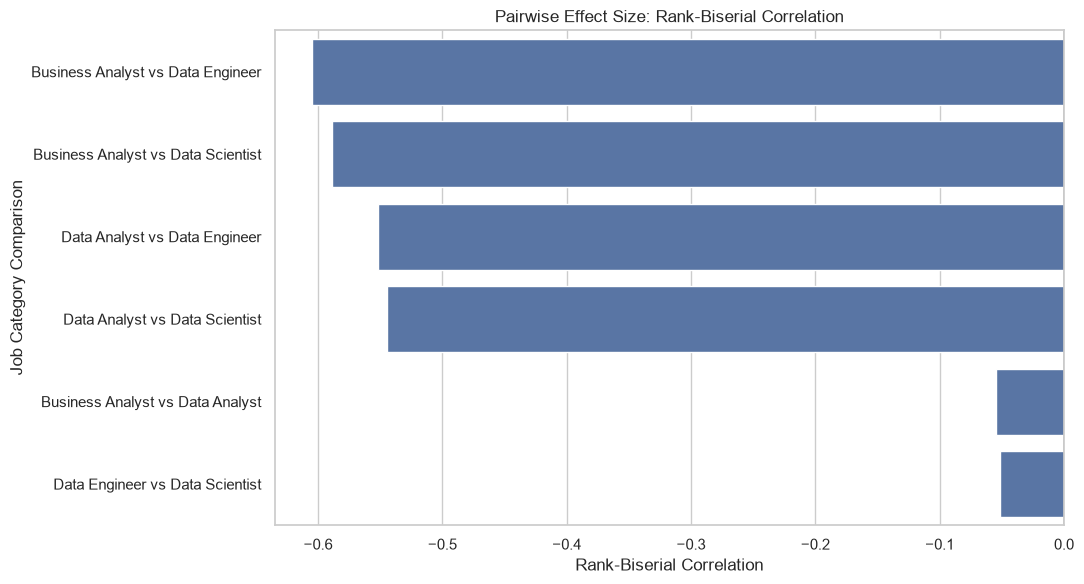

In [16]:
plt.figure(figsize=(11, 6))

plot_data = effect_size_df.copy()

plot_data['comparison'] = (
    plot_data['category_1'] + ' vs ' +
    plot_data['category_2']
)

plot_data = plot_data.sort_values('rank_biserial')

sns.barplot(
    data=plot_data,
    x='rank_biserial',
    y='comparison'
)

plt.axvline(0, color='black', linewidth=1)
plt.title('Pairwise Effect Size: Rank-Biserial Correlation')
plt.xlabel('Rank-Biserial Correlation')
plt.ylabel('Job Category Comparison')
plt.tight_layout()
plt.show()


## 7. Conclusion and Key Findings

### 7.1 Descriptive Findings

The descriptive analysis shows differences in annual salary distributions across the four job categories.

- Data Scientist has the highest median annual salary at **$127,500**.
- Data Engineer follows with a median of **$125,000**.
- Data Analyst has a median annual salary of **$90,000**.
- Business Analyst has the lowest median annual salary at **$85,000**.

All four categories exhibit positively skewed salary distributions, indicating that a relatively small number of high-paying positions influence their mean salaries. Therefore, the median provides a more representative measure of typical salary levels than the mean.

### 7.2 Overall Statistical Test

The Kruskal-Wallis H test indicates a statistically significant difference in salary distributions across the four job categories:

- H-statistic: **3530.8072**
- p-value: **p < 0.001**
- Epsilon-squared: **0.2137**

The null hypothesis is rejected. This suggests that at least one job category has a different salary distribution from the others.

The epsilon-squared value of 0.2137 indicates a meaningful difference in rank distributions across the categories.

### 7.3 Pairwise Post-hoc Analysis

Pairwise Mann-Whitney U tests with Holm correction show that all six category comparisons are statistically significant at the 0.05 significance level.

However, statistical significance alone does not indicate that every pair has a substantial difference.

The adjusted p-values show that the observed differences are unlikely to be explained by random sampling variation under the null hypotheses.

### 7.4 Pairwise Effect Size

Rank-biserial correlation provides additional information about the magnitude and direction of pairwise differences.

The results indicate:

- **BA vs DA:** Small effect size (|r| = 0.0544).
- **DE vs DS:** Small effect size (|r| = 0.0514).
- **BA vs DE, BA vs DS, DA vs DE, and DA vs DS:** Larger effect sizes, with absolute values ranging from approximately 0.54 to 0.60.

The negative effect sizes indicate that the first category in each comparison generally has lower salary ranks than the second category.

These results suggest that some job categories have substantially different salary distributions, while others have statistically significant but relatively small differences.

### 7.5 Limitations

Several limitations should be considered when interpreting these findings:

1. **Salary coverage:** Only a subset of job postings contains annual salary information. The analysis may therefore reflect the characteristics of jobs that disclose salaries rather than the entire job market.
2. **Geographic differences:** Salaries may vary considerably across countries and regions. This analysis does not control for location.
3. **Experience and seniority:** Differences in experience requirements and seniority may contribute to salary variation.
4. **Distribution characteristics:** The Kruskal-Wallis and Mann-Whitney U tests compare rank distributions, not exclusively median values.
5. **Dataset period:** The dataset represents job postings from 2023 and should not be interpreted as a direct representation of the current job market.

### 7.6 Final Conclusion

The statistical analysis identifies differences in annual salary distributions among Business Analyst, Data Analyst, Data Engineer, and Data Scientist positions.

Data Scientist and Data Engineer positions have higher median annual salaries than Data Analyst and Business Analyst positions in this dataset. Although all pairwise comparisons are statistically significant, effect sizes reveal that the magnitude of these differences varies.

Overall, job category is associated with differences in salary distributions. However, salary should not be interpreted as being determined by job category alone, since factors such as geographic location, experience, seniority, and company characteristics are not controlled for in this analysis.
